In [35]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, ConfusionMatrixDisplay
from tabulate import tabulate

import load.load_dataset as ds
import load.load_net as nt

import joblib

In [36]:
def ovr_roc(y_onehot, proba):
    if proba.shape[1] == 2:
        y, p = y_onehot[:, 1], proba[:, 1]
    else:
        y, p = y_onehot.ravel(), proba.ravel()
    fpr, tpr, _ = roc_curve(y, p)
    return roc_auc_score(y, p), fpr, tpr

def plot_roc(y_val, result1, result2, result3, result4, result5, result6, dataset_name):
    y_onehot = y_val.detach().numpy()

    roc1, fpr1, tpr1 = ovr_roc(y_onehot, result1['pred_proba'][0])
    roc2, fpr2, tpr2 = ovr_roc(y_onehot, result2['pred_proba'][0])
    roc3, fpr3, tpr3 = ovr_roc(y_onehot, result3['pred_proba'][0])
    roc4, fpr4, tpr4 = ovr_roc(y_onehot, result4['pred_proba'][0])
    roc5, fpr5, tpr5 = ovr_roc(y_onehot, result5['pred_proba'][0])
    roc6, fpr6, tpr6 = ovr_roc(y_onehot, result6['pred_proba'][0])

    fig, ax = plt.subplots(1, 3, figsize=(18, 6))

    plt.figure(figsize=(6,6))
    ax[0].set_title('SmallNN')
    ax[0].plot(fpr1, tpr1, color='black', label=f'Small - {roc1:.4f}')
    ax[0].plot(fpr4, tpr4, color='red', label=f'Regularized - {roc4:.4f}')
    ax[0].plot([0,1],[0,1], color='grey', linestyle='--', label='Random')
    ax[0].set_xlabel('False Positive Rate')
    ax[0].set_ylabel('True Positive Rate')
    ax[0].legend()

    ax[1].set_title('DeeperNN')
    ax[1].plot(fpr2, tpr2, color='black', label=f'Deeper - {roc2:.4f}')
    ax[1].plot(fpr5, tpr5, color='red', label=f'Regularized - {roc5:.4f}')
    ax[1].plot([0,1],[0,1], color='grey', linestyle='--', label='Random')
    ax[1].set_xlabel('False Positive Rate')
    ax[1].set_ylabel('True Positive Rate')
    ax[1].legend()

    ax[2].set_title('ShallowNN')
    ax[2].plot(fpr3, tpr3, color='black', label=f'Shallow - {roc3:.4f}')
    ax[2].plot(fpr6, tpr6, color='red', label=f'Regularized - {roc6:.4f}')
    ax[2].plot([0,1],[0,1], color='grey', linestyle='--', label='Random')
    ax[2].set_xlabel('False Positive Rate')
    ax[2].set_ylabel('True Positive Rate')
    ax[2].legend()

    plt.tight_layout()
    plt.show()

    return [roc1, roc2, roc3, roc4, roc5, roc6]


In [37]:
def plot_conf_matrix(y_val, result1, result2, result3, title = ['', '', '']):
    cm1 = result1['confusion_matrix'][0]
    cm2 = result2['confusion_matrix'][0]
    cm3 = result3['confusion_matrix'][0]
    fig, ax = plt.subplots(1, 3, figsize=(18, 6))
    disp1 = ConfusionMatrixDisplay(confusion_matrix=cm1)
    disp2 = ConfusionMatrixDisplay(confusion_matrix=cm2)
    disp3 = ConfusionMatrixDisplay(confusion_matrix=cm3)
    ax[0].set_title(title[0])
    ax[1].set_title(title[1])
    ax[2].set_title(title[2])
    disp1.plot(cmap=plt.cm.Blues, ax=ax[0])
    disp2.plot(cmap=plt.cm.Blues, ax=ax[1])
    disp3.plot(cmap=plt.cm.Blues, ax=ax[2])
    ax[0].grid(False)
    ax[1].grid(False)
    ax[2].grid(False)
    plt.show()

In [38]:
def eval_net(dataset_name, model_name, verbose = False, print_report = False):

    history = joblib.load(f'./models/histories/{dataset_name}_{model_name}_history.joblib')
    results = joblib.load(f'./models/results/{dataset_name}_{model_name}_results.joblib')
    acc_train = history['train_acc'][-1]
    acc_val = history['val_acc'][-1]

    if verbose:
        print(model_name)
        axis = np.linspace(0, len(history['train_loss']), len(history['train_loss']))
        fig, ax = plt.subplots(1, 2, figsize = [12,5])
        ax[0].plot(axis, history['train_loss'], label='Train Loss')
        ax[0].plot(axis, history['val_loss'], label='Val Loss')
        ax[0].set_title('Loss')
        ax[0].legend()

        ax[1].plot(axis, history['train_acc'], label='Train Accuracy')
        ax[1].plot(axis, history['val_acc'], label='Val Accuracy')
        ax[1].set_title('Accuracy')
        ax[1].legend()
        plt.tight_layout()
        plt.show()
    if print_report:
        print(f"\n{model_name}")
        print(results['classification_report'][0])
    return results, acc_train, acc_val


# Models

In [39]:
read = joblib.load('../load/nets/model_adult_dict.joblib')
read
# in the case of adult, similarly for other datasets

{'model1': smallNN(
   (linear1): Linear(in_features=97, out_features=256, bias=True)
   (sigmoid1): ReLU()
   (linear2): Linear(in_features=256, out_features=128, bias=True)
   (sigmoid2): ReLU()
   (linear3): Linear(in_features=128, out_features=64, bias=True)
   (sigmoid3): ReLU()
   (linear4): Linear(in_features=64, out_features=32, bias=True)
   (sigmoid4): ReLU()
   (linear5): Linear(in_features=32, out_features=2, bias=True)
   (softmax): Softmax(dim=None)
 ),
 'model2': deeperNN(
   (linear1): Linear(in_features=97, out_features=1024, bias=True)
   (relu1): ReLU()
   (linear2): Linear(in_features=1024, out_features=512, bias=True)
   (relu2): ReLU()
   (linear3): Linear(in_features=512, out_features=128, bias=True)
   (relu3): ReLU()
   (linear4): Linear(in_features=128, out_features=64, bias=True)
   (relu4): ReLU()
   (linear5): Linear(in_features=64, out_features=32, bias=True)
   (relu5): ReLU()
   (linear6): Linear(in_features=32, out_features=2, bias=True)
   (softmax): S

In [40]:
# regularized models to be compared

models_list = ['model1', 'model2', 'model3', 'model1r', 'model2r', 'model3r']
#models_list = ['model1', 'model2', 'model3', 'model1bn', 'model2bn', 'model3bn']
#models_list = ['model1', 'model2', 'model3', 'model1do1', 'model2do1', 'model3do1']


# ADULT

structure of the nets for dataset adult:

In [41]:
dataset_name = "adult"
net = nt.load_net(dataset_name)
dataset = ds.Dataset(dataset_name)

feature_names, categorical_features, categorical_names, ordinal, discrete, encoder, num_features = dataset.info()
X_train_or, X_train, y_train = dataset.train()
X_val_or, X_val, y_val = dataset.validation()
X_test_or, X_test, y_test = dataset.test()
print(X_train_or.shape, X_val_or.shape, X_test_or.shape)

adult_smallNN, adult_acc_train_model1, adult_acc_val_model1 = eval_net(dataset_name, models_list[0])
adult_deeperNN, adult_acc_train_model2, adult_acc_val_model2 = eval_net(dataset_name, models_list[1])
adult_shallowNN, adult_acc_train_model3, adult_acc_val_model3 = eval_net(dataset_name, models_list[2])

adult_regSmallNN, adult_acc_train_model1r, adult_acc_val_model1r = eval_net(dataset_name, models_list[3])
adult_regDeeperNN, adult_acc_train_model2r, adult_acc_val_model2r = eval_net(dataset_name, models_list[4])
adult_regShallowNN, adult_acc_train_model3r, adult_acc_val_model3r = eval_net(dataset_name, models_list[5])

(36177, 12) (8045, 12) (1000, 12)


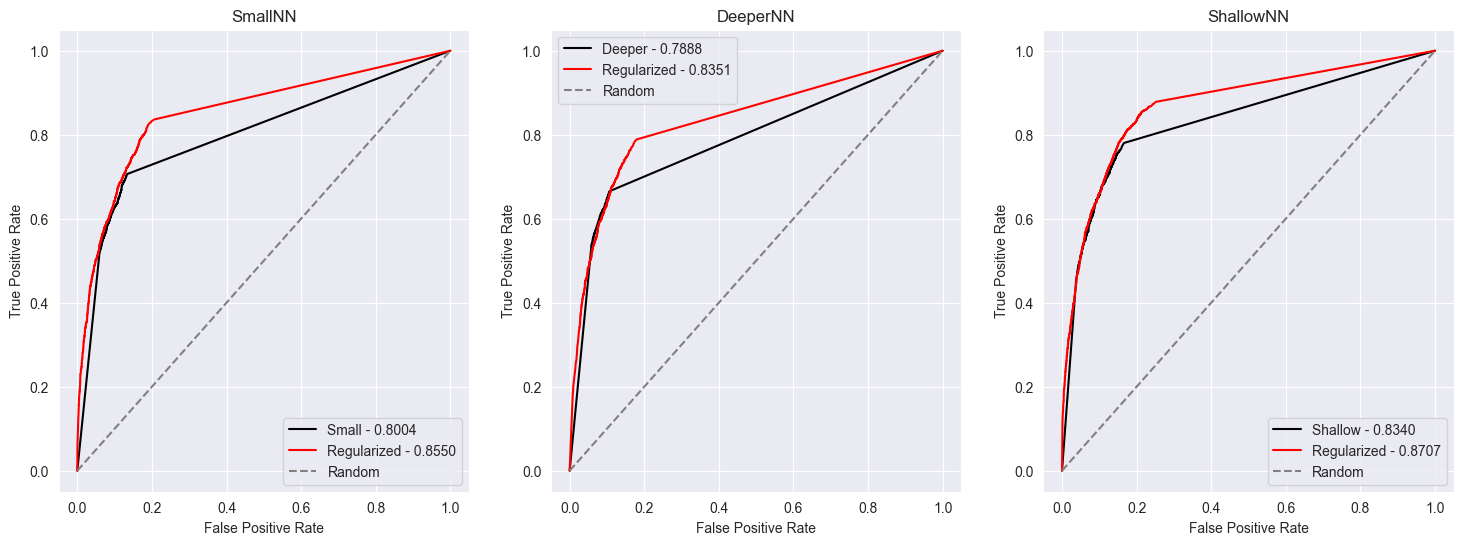

<Figure size 600x600 with 0 Axes>

In [42]:
roc_adult = plot_roc(y_val, adult_smallNN, adult_deeperNN, adult_shallowNN, adult_regSmallNN, adult_regDeeperNN, adult_regShallowNN, dataset_name)

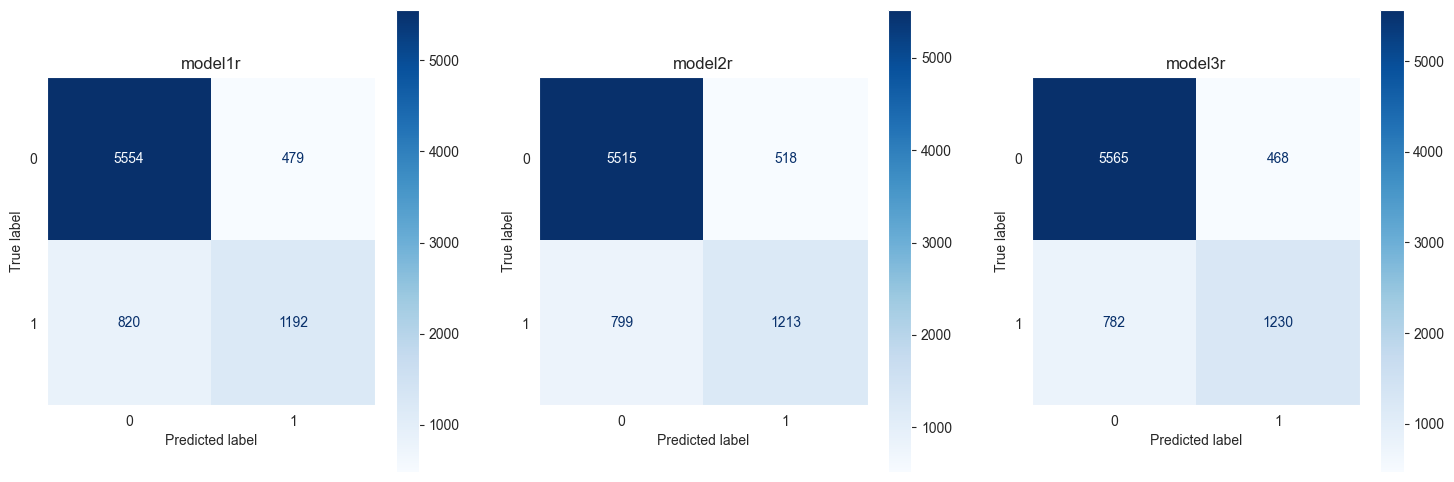

In [43]:
plot_conf_matrix(y_val, adult_regSmallNN, adult_regDeeperNN, adult_regShallowNN, title = [models_list[3], models_list[4], models_list[5]])

# BANK

In [44]:
dataset_name = "bank"
net = nt.load_net(dataset_name)
dataset = ds.Dataset(dataset_name)

feature_names, categorical_features, categorical_names, ordinal, discrete, encoder, num_features = dataset.info()
X_train_or, X_train, y_train = dataset.train()
X_val_or, X_val, y_val = dataset.validation()
X_test_or, X_test, y_test = dataset.test()
print(X_train_or.shape, X_val_or.shape, X_test_or.shape)

bank_smallNN, bank_acc_train_model1, bank_acc_val_model1 = eval_net(dataset_name, models_list[0])
bank_deeperNN, bank_acc_train_model2, bank_acc_val_model2 = eval_net(dataset_name, models_list[1])
bank_shallowNN, bank_acc_train_model3, bank_acc_val_model3 = eval_net(dataset_name, models_list[2])

bank_regSmallNN, bank_acc_train_model1r, bank_acc_val_model1r = eval_net(dataset_name, models_list[3])
bank_regDeeperNN, bank_acc_train_model2r, bank_acc_val_model2r = eval_net(dataset_name, models_list[4])
bank_regShallowNN, bank_acc_train_model3r, bank_acc_val_model3r = eval_net(dataset_name, models_list[5])

(36168, 14) (8043, 14) (1000, 14)


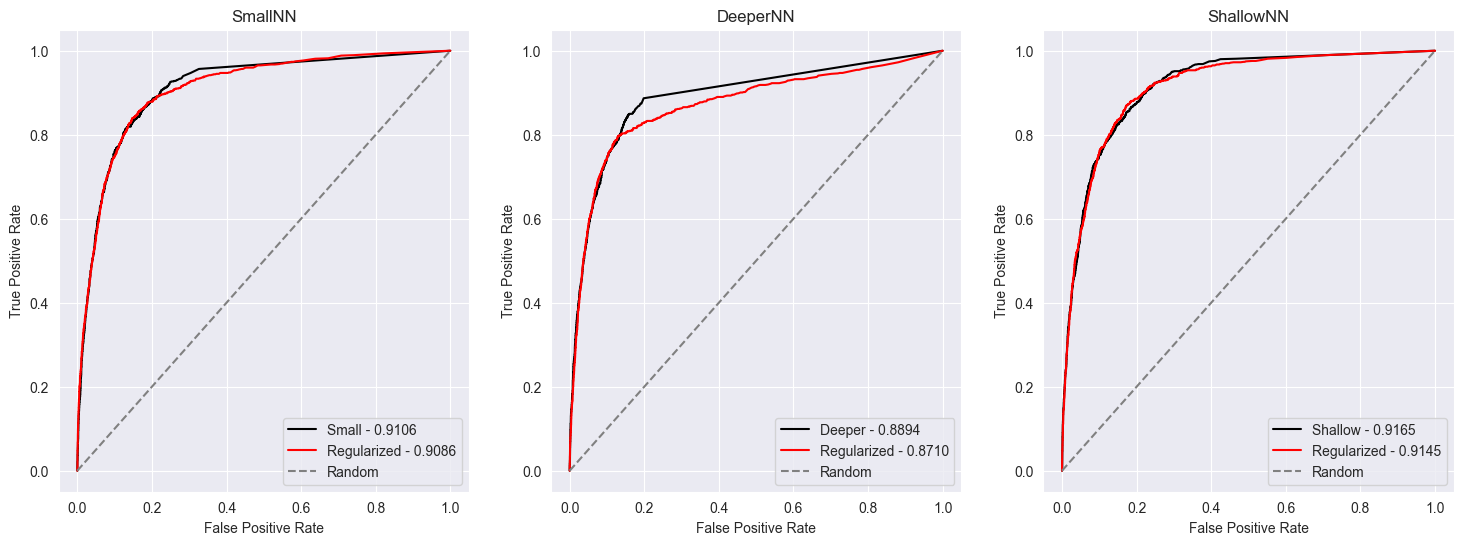

<Figure size 600x600 with 0 Axes>

In [45]:
roc_bank = plot_roc(y_val, bank_smallNN, bank_deeperNN, bank_shallowNN, bank_regSmallNN, bank_regDeeperNN, bank_regShallowNN, dataset_name)

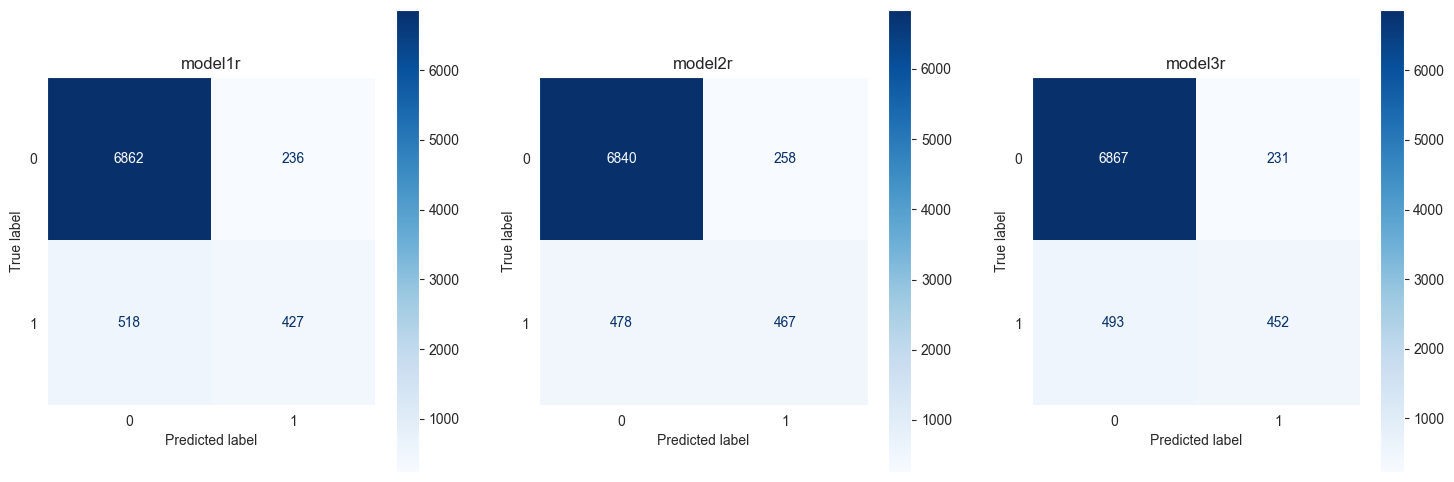

In [46]:
plot_conf_matrix(y_val, bank_regSmallNN, bank_regDeeperNN, bank_regShallowNN, title = [models_list[3], models_list[4], models_list[5]])

# BEANS

In [47]:
dataset_name = "beans"
net = nt.load_net(dataset_name)
dataset = ds.Dataset(dataset_name)

feature_names, categorical_features, categorical_names, ordinal, discrete, encoder, num_features = dataset.info()
X_train_or, X_train, y_train = dataset.train()
X_val_or, X_val, y_val = dataset.validation()
X_test_or, X_test, y_test = dataset.test()
print(X_train_or.shape, X_val_or.shape, X_test_or.shape)

beans_smallNN, beans_acc_train_model1, beans_acc_val_model1 = eval_net(dataset_name, models_list[0])
beans_deeperNN, beans_acc_train_model2, beans_acc_val_model2 = eval_net(dataset_name, models_list[1])
beans_shallowNN, beans_acc_train_model3, beans_acc_val_model3 = eval_net(dataset_name, models_list[2])

beans_regSmallNN, beans_acc_train_model1r, beans_acc_val_model1r = eval_net(dataset_name, models_list[3])
beans_regDeeperNN, beans_acc_train_model2r, beans_acc_val_model2r = eval_net(dataset_name, models_list[4])
beans_regShallowNN, beans_acc_train_model3r, beans_acc_val_model3r = eval_net(dataset_name, models_list[5])

(10888, 7) (2223, 7) (500, 7)


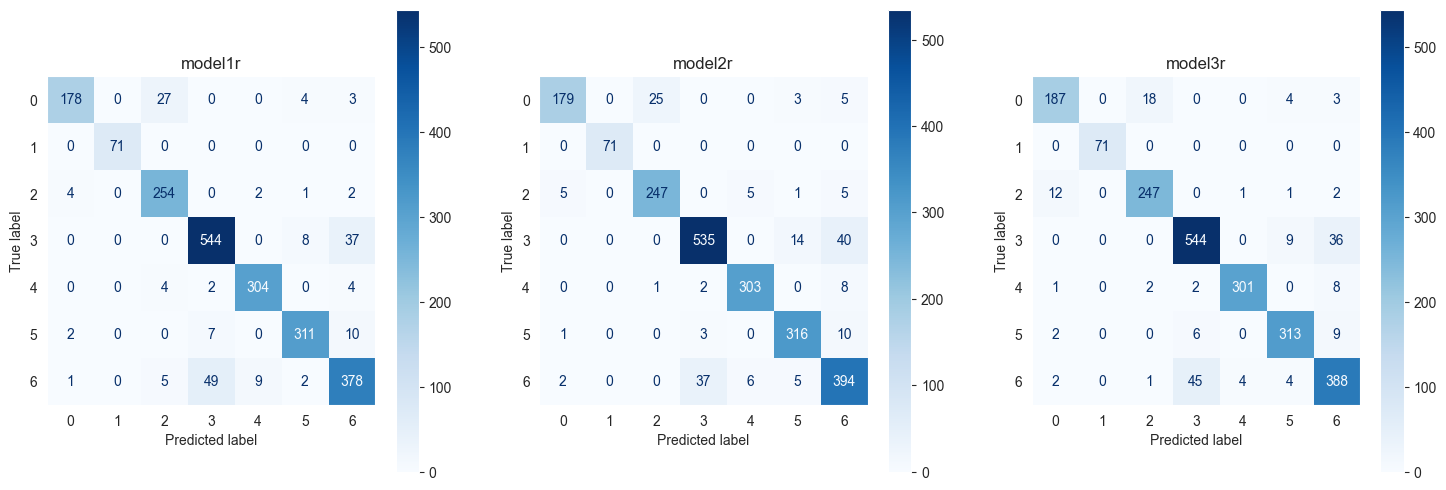

In [48]:
plot_conf_matrix(y_val, beans_regSmallNN, beans_regDeeperNN, beans_regShallowNN, title = [models_list[3], models_list[4], models_list[5]])

# CANCER

In [49]:
dataset_name = "cancer"
net = nt.load_net(dataset_name)
dataset = ds.Dataset(dataset_name)

feature_names, categorical_features, categorical_names, ordinal, discrete, encoder, num_features = dataset.info()
X_train_or, X_train, y_train = dataset.train()
X_val_or, X_val, y_val = dataset.validation()
X_test_or, X_test, y_test = dataset.test()
print(X_train_or.shape, X_val_or.shape, X_test_or.shape)

cancer_smallNN, cancer_acc_train_model1, cancer_acc_val_model1 = eval_net(dataset_name, models_list[0])
cancer_deeperNN, cancer_acc_train_model2, cancer_acc_val_model2 = eval_net(dataset_name, models_list[1])
cancer_shallowNN, cancer_acc_train_model3, cancer_acc_val_model3 = eval_net(dataset_name, models_list[2])

cancer_regSmallNN, cancer_acc_train_model1r, cancer_acc_val_model1r = eval_net(dataset_name, models_list[3])
cancer_regDeeperNN, cancer_acc_train_model2r, cancer_acc_val_model2r = eval_net(dataset_name, models_list[4])
cancer_regShallowNN, cancer_acc_train_model3r, cancer_acc_val_model3r = eval_net(dataset_name, models_list[5])

(397, 15) (121, 15) (50, 15)


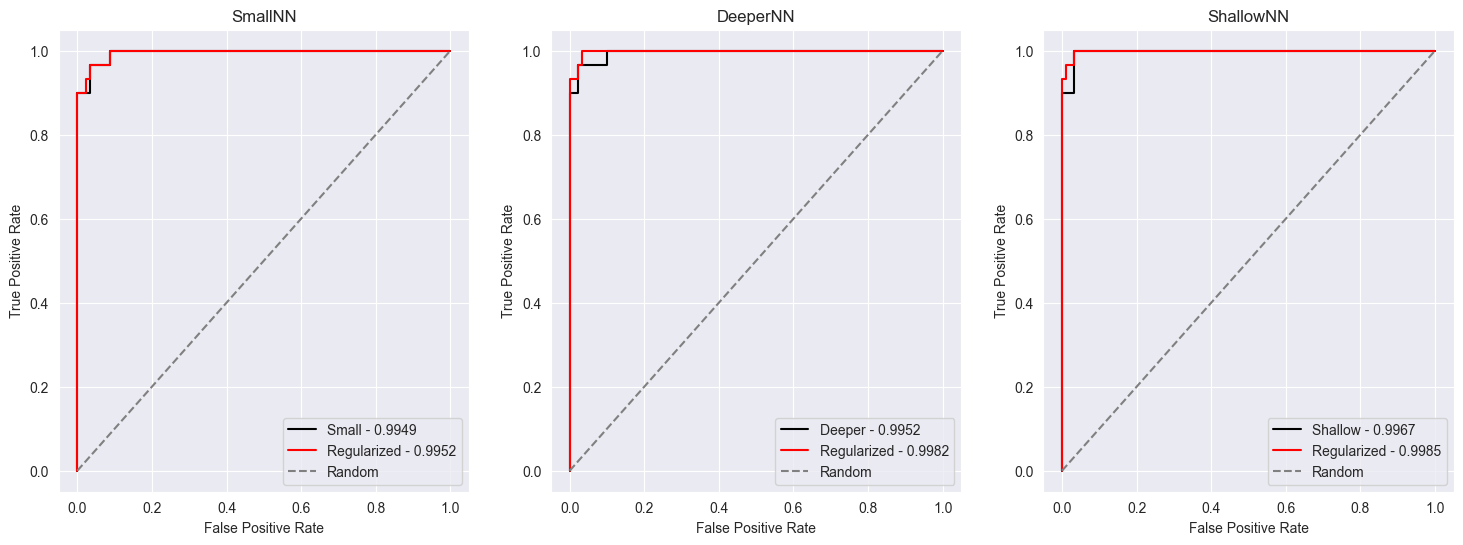

<Figure size 600x600 with 0 Axes>

In [50]:
roc_cancer = plot_roc(y_val, cancer_smallNN, cancer_deeperNN, cancer_shallowNN, cancer_regSmallNN, cancer_regDeeperNN, cancer_regShallowNN, dataset_name)

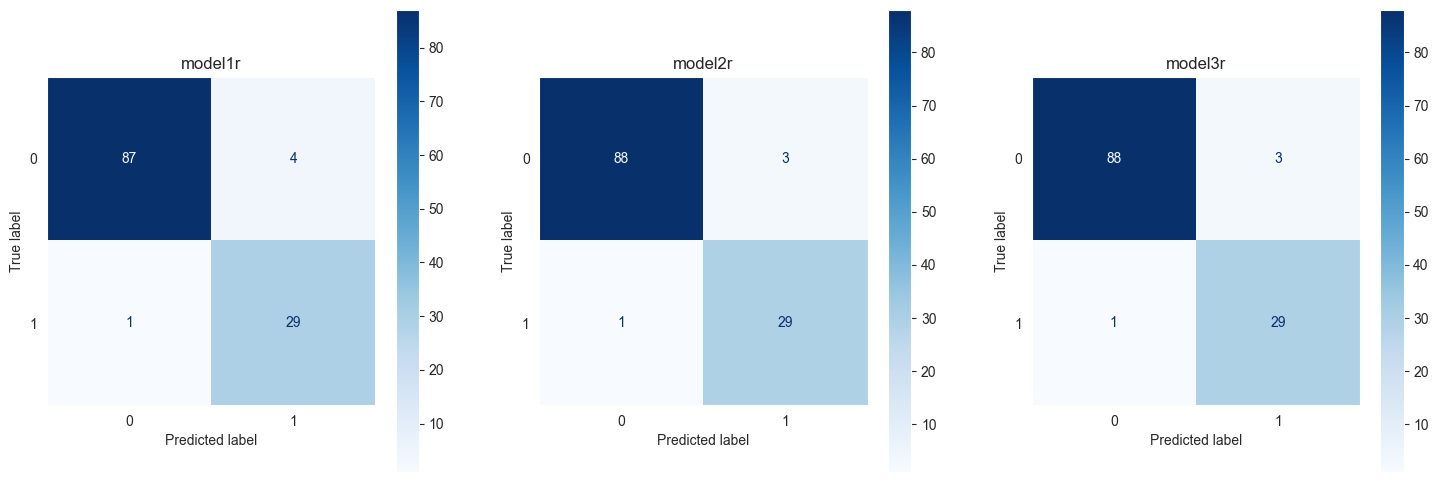

In [51]:
plot_conf_matrix(y_val, cancer_regSmallNN, cancer_regDeeperNN, cancer_regShallowNN, title = [models_list[3], models_list[4], models_list[5]])

# HELOC

In [52]:
dataset_name = "heloc"
net = nt.load_net(dataset_name)
dataset = ds.Dataset(dataset_name)

feature_names, categorical_features, categorical_names, ordinal, discrete, encoder, num_features = dataset.info()
X_train_or, X_train, y_train = dataset.train()
X_val_or, X_val, y_val = dataset.validation()
X_test_or, X_test, y_test = dataset.test()
print(X_train_or.shape, X_val_or.shape, X_test_or.shape)

heloc_smallNN, heloc_acc_train_model1, heloc_acc_val_model1 = eval_net(dataset_name, models_list[0])
heloc_deeperNN, heloc_acc_train_model2, heloc_acc_val_model2 = eval_net(dataset_name, models_list[1])
heloc_shallowNN, heloc_acc_train_model3, heloc_acc_val_model3 = eval_net(dataset_name, models_list[2])

heloc_regSmallNN, heloc_acc_train_model1r, heloc_acc_val_model1r = eval_net(dataset_name, models_list[3])
heloc_regDeeperNN, heloc_acc_train_model2r, heloc_acc_val_model2r = eval_net(dataset_name, models_list[4])
heloc_regShallowNN, heloc_acc_train_model3r, heloc_acc_val_model3r = eval_net(dataset_name, models_list[5])

(8367, 16) (1592, 16) (500, 16)


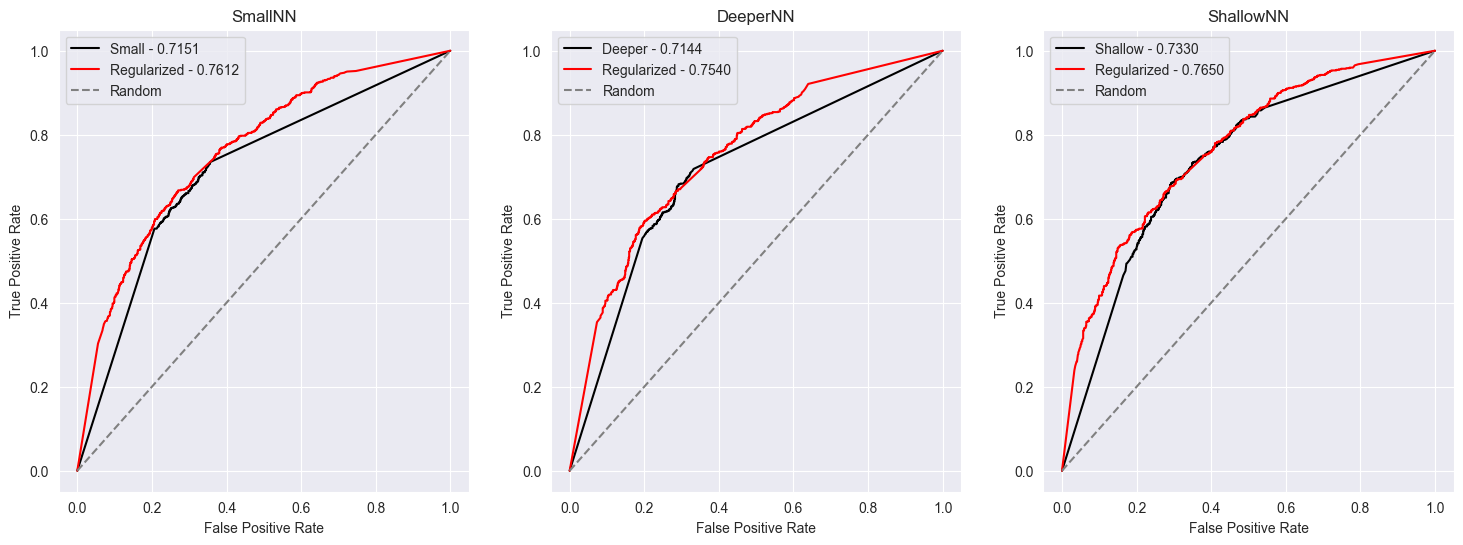

<Figure size 600x600 with 0 Axes>

In [53]:
roc_heloc = plot_roc(y_val, heloc_smallNN, heloc_deeperNN, heloc_shallowNN, heloc_regSmallNN, heloc_regDeeperNN, heloc_regShallowNN, dataset_name)

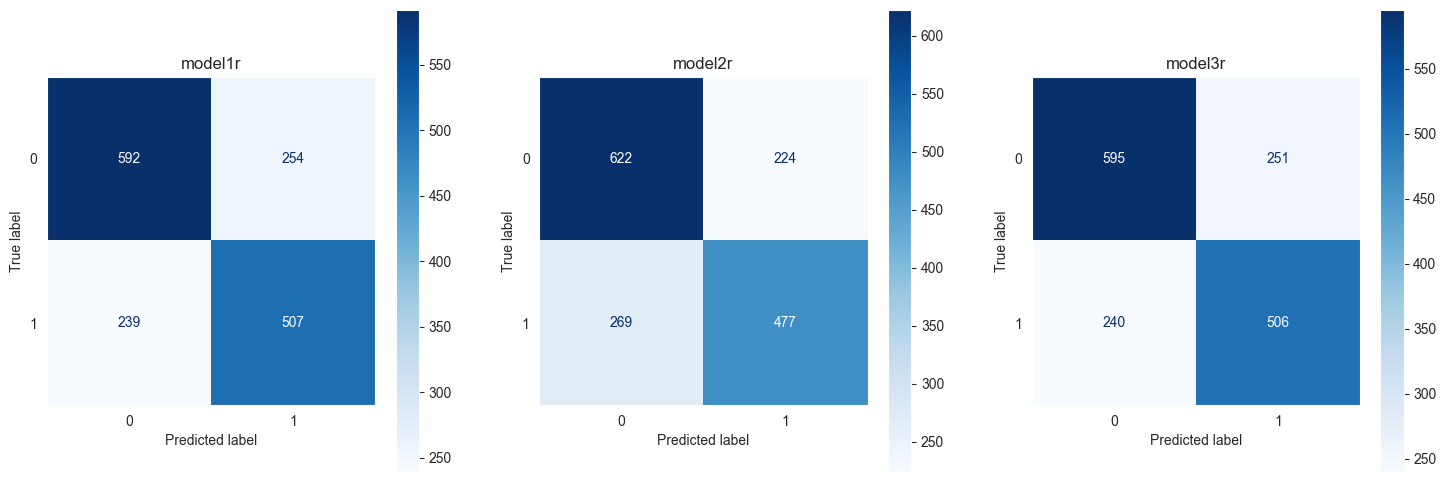

In [54]:
plot_conf_matrix(y_val, heloc_regSmallNN, heloc_regDeeperNN, heloc_regShallowNN, title = [models_list[3], models_list[4], models_list[5]])

# MUSHROOMS

In [55]:
dataset_name = "mushroom"
net = nt.load_net(dataset_name)
dataset = ds.Dataset(dataset_name)

feature_names, categorical_features, categorical_names, ordinal, discrete, encoder, num_features = dataset.info()
X_train_or, X_train, y_train = dataset.train()
X_val_or, X_val, y_val = dataset.validation()
X_test_or, X_test, y_test = dataset.test()
print(X_train_or.shape, X_val_or.shape, X_test_or.shape)

mushroom_smallNN, mushroom_acc_train_model1, mushroom_acc_val_model1 = eval_net(dataset_name, models_list[0])
mushroom_deeperNN, mushroom_acc_train_model2, mushroom_acc_val_model2 = eval_net(dataset_name, models_list[1])
mushroom_shallowNN, mushroom_acc_train_model3, mushroom_acc_val_model3 = eval_net(dataset_name, models_list[2])

mushroom_regSmallNN, mushroom_acc_train_model1r, mushroom_acc_val_model1r = eval_net(dataset_name, models_list[3])
mushroom_regDeeperNN, mushroom_acc_train_model2r, mushroom_acc_val_model2r = eval_net(dataset_name, models_list[4])
mushroom_regShallowNN, mushroom_acc_train_model3r, mushroom_acc_val_model3r = eval_net(dataset_name, models_list[5])

(6498, 21) (1225, 21) (400, 21)


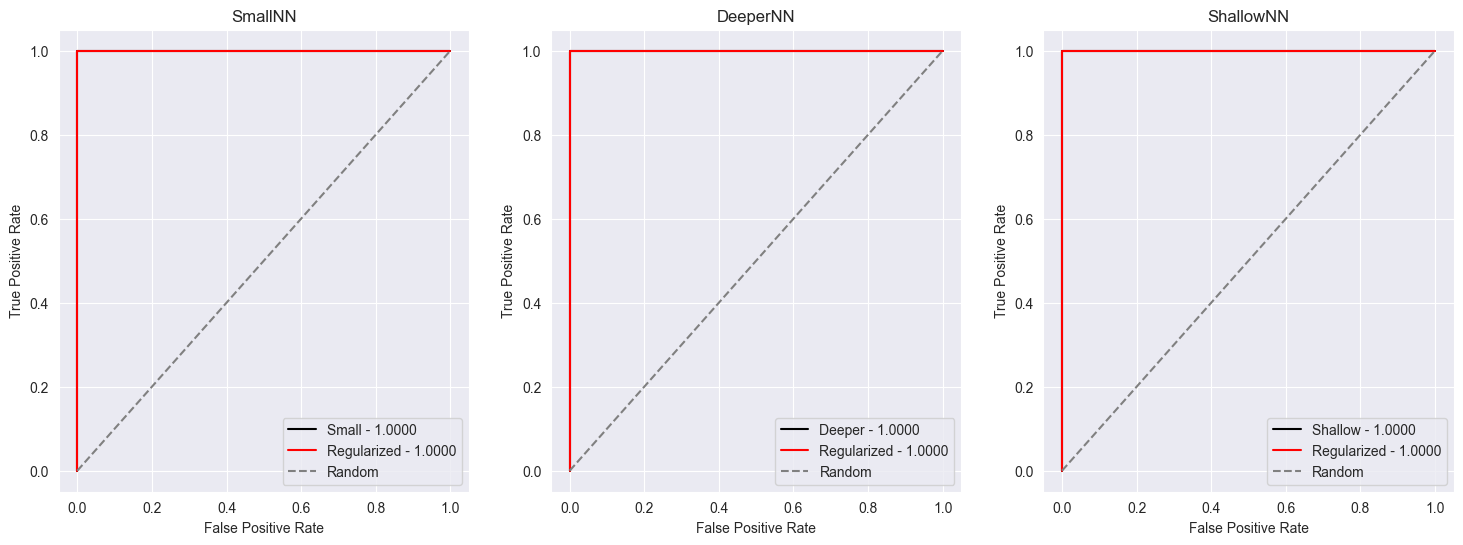

<Figure size 600x600 with 0 Axes>

In [56]:
roc_mushroom = plot_roc(y_val, mushroom_smallNN, mushroom_deeperNN, mushroom_shallowNN, mushroom_regSmallNN, mushroom_regDeeperNN, mushroom_regShallowNN, dataset_name)

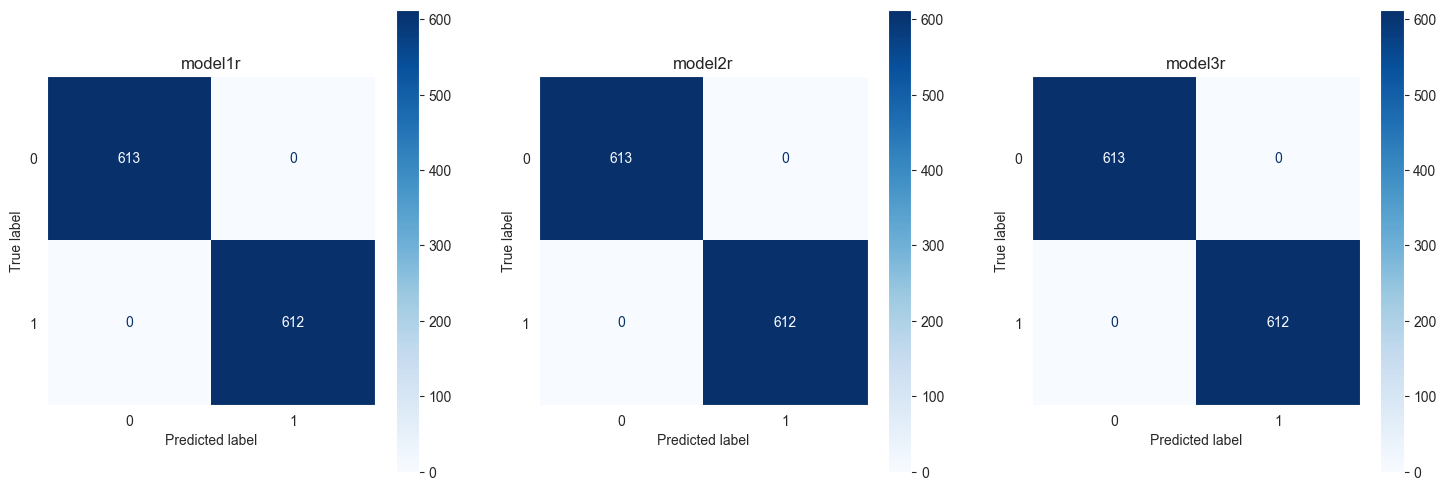

In [57]:
plot_conf_matrix(y_val, mushroom_regSmallNN, mushroom_regDeeperNN, mushroom_regShallowNN, title = [models_list[3], models_list[4], models_list[5]])

# OCEAN

In [58]:
dataset_name = "ocean"
net = nt.load_net(dataset_name)
dataset = ds.Dataset(dataset_name)

feature_names, categorical_features, categorical_names, ordinal, discrete, encoder, num_features = dataset.info()
X_train_or, X_train, y_train = dataset.train()
X_val_or, X_val, y_val = dataset.validation()
X_test_or, X_test, y_test = dataset.test()
print(X_train_or.shape, X_val_or.shape, X_test_or.shape)

ocean_smallNN, ocean_acc_train_model1, ocean_acc_val_model1 = eval_net(dataset_name, models_list[0])
ocean_deeperNN, ocean_acc_train_model2, ocean_acc_val_model2 = eval_net(dataset_name, models_list[1])
ocean_shallowNN, ocean_acc_train_model3, ocean_acc_val_model3 = eval_net(dataset_name, models_list[2])

ocean_regSmallNN, ocean_acc_train_model1r, ocean_acc_val_model1r = eval_net(dataset_name, models_list[3])
ocean_regDeeperNN, ocean_acc_train_model2r, ocean_acc_val_model2r = eval_net(dataset_name, models_list[4])
ocean_regShallowNN, ocean_acc_train_model3r, ocean_acc_val_model3r = eval_net(dataset_name, models_list[5])

(109259, 8) (30328, 8) (10000, 8)


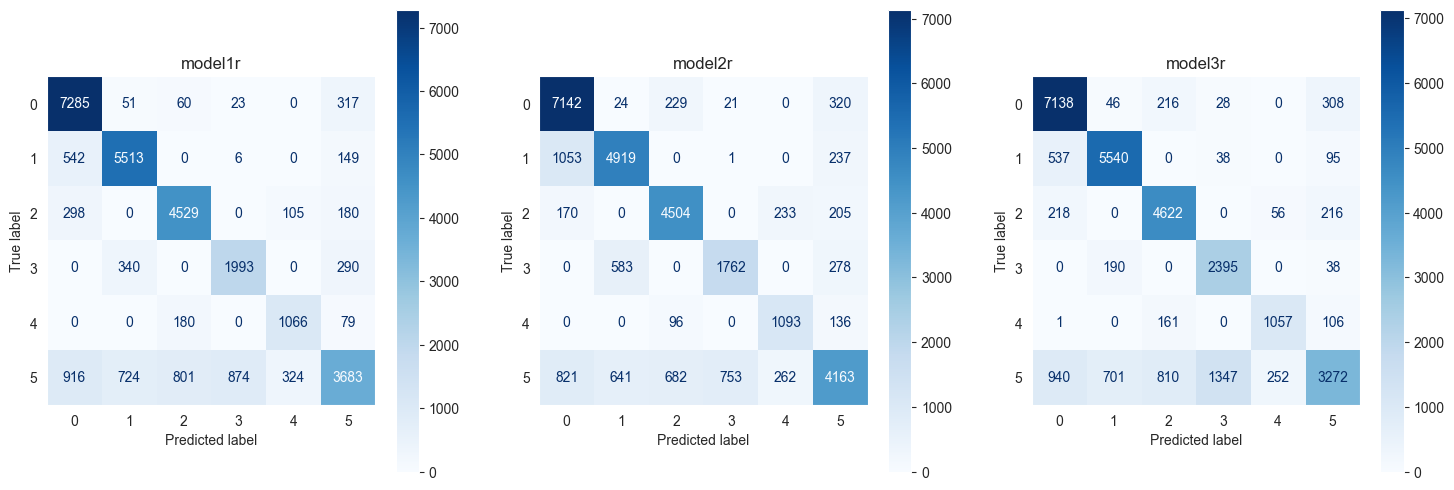

In [59]:
plot_conf_matrix(y_val, ocean_regSmallNN, ocean_regDeeperNN, ocean_regShallowNN, title = [models_list[3], models_list[4], models_list[5]])

# WINE

In [60]:
dataset_name = "wine"
net = nt.load_net(dataset_name)
dataset = ds.Dataset(dataset_name)

feature_names, categorical_features, categorical_names, ordinal, discrete, encoder, num_features = dataset.info()
X_train_or, X_train, y_train = dataset.train()
X_val_or, X_val, y_val = dataset.validation()
X_test_or, X_test, y_test = dataset.test()
print(X_train_or.shape, X_val_or.shape, X_test_or.shape)

wine_smallNN, wine_acc_train_model1, wine_acc_val_model1 = eval_net(dataset_name, models_list[0])
wine_deeperNN, wine_acc_train_model2, wine_acc_val_model2 = eval_net(dataset_name, models_list[1])
wine_shallowNN, wine_acc_train_model3, wine_acc_val_model3 = eval_net(dataset_name, models_list[2])

wine_regSmallNN, wine_acc_train_model1r, wine_acc_val_model1r = eval_net(dataset_name, models_list[3])
wine_regDeeperNN, wine_acc_train_model2r, wine_acc_val_model2r = eval_net(dataset_name, models_list[4])
wine_regShallowNN, wine_acc_train_model3r, wine_acc_val_model3r = eval_net(dataset_name, models_list[5])

(3918, 9) (780, 9) (200, 9)


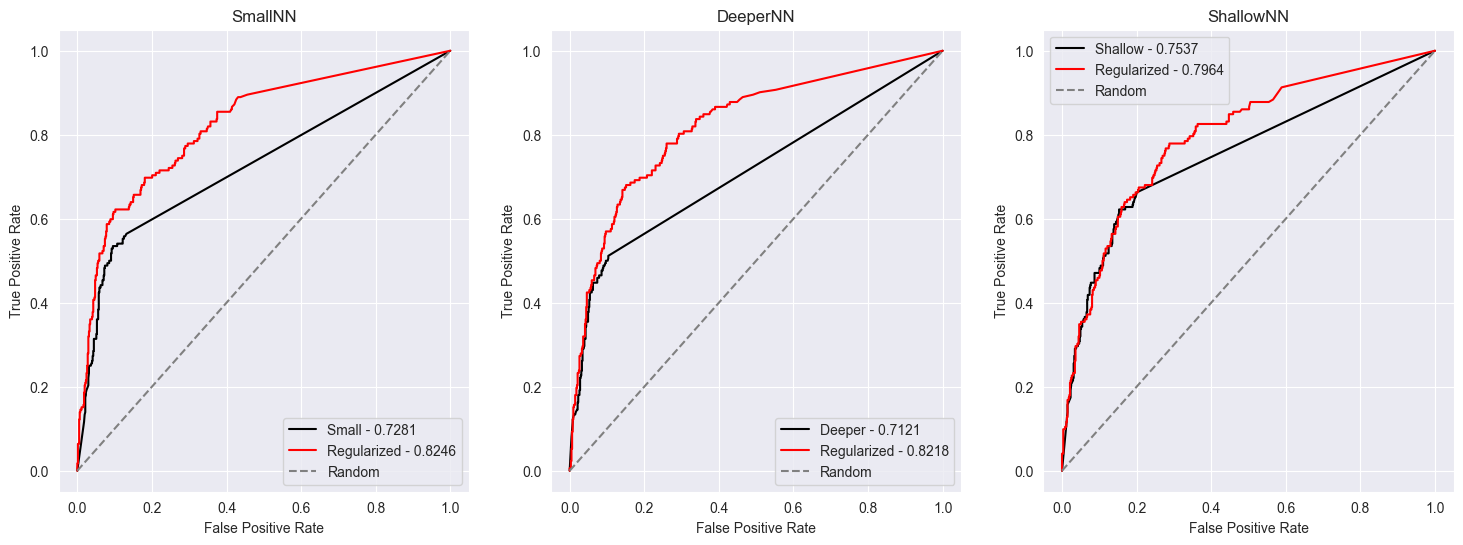

<Figure size 600x600 with 0 Axes>

In [61]:
roc_wine = plot_roc(y_val, wine_smallNN, wine_deeperNN, wine_shallowNN, wine_regSmallNN, wine_regDeeperNN, wine_regShallowNN, dataset_name)

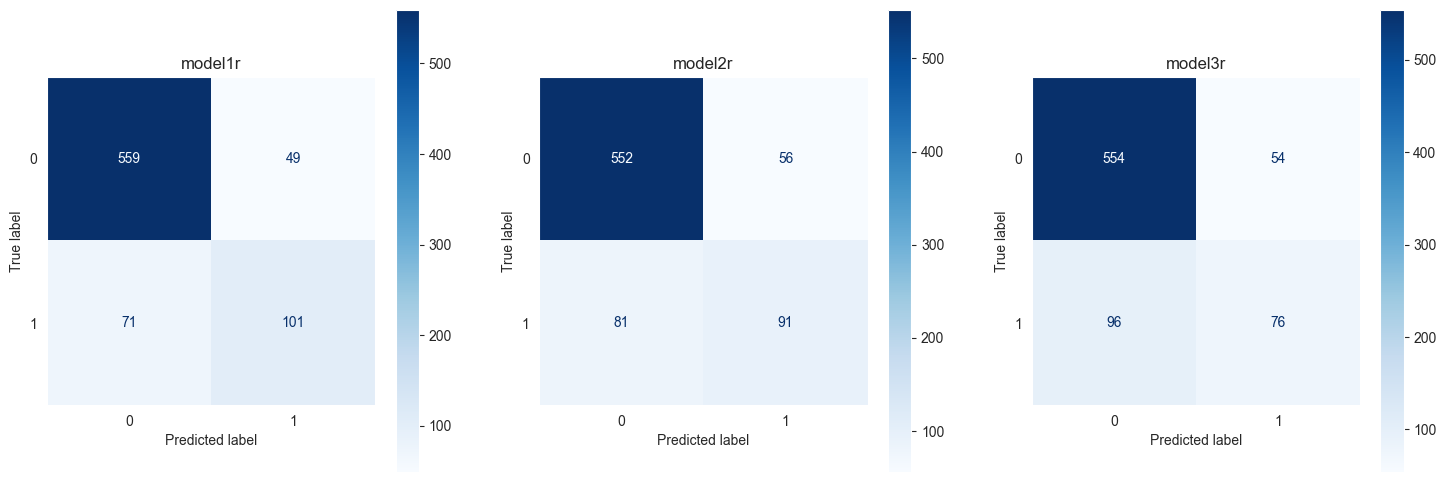

In [62]:
plot_conf_matrix(y_val, wine_regSmallNN, wine_regDeeperNN, wine_regShallowNN, title = [models_list[3], models_list[4], models_list[5]])

# Model accuracy comparability

In [63]:
set = 'val'
print(f"    {set}\n")

if set == 'val':
    data = [
        ["adult", adult_acc_val_model1, adult_acc_val_model2, adult_acc_val_model3, adult_acc_val_model1r, adult_acc_val_model2r, adult_acc_val_model3r],
        ["bank", bank_acc_val_model1, bank_acc_val_model2, bank_acc_val_model3, bank_acc_val_model1r, bank_acc_val_model2r, bank_acc_val_model3r],
        ["beans", beans_acc_val_model1, beans_acc_val_model2, beans_acc_val_model3, beans_acc_val_model1r, beans_acc_val_model2r, beans_acc_val_model3r],
        ["cancer", cancer_acc_val_model1, cancer_acc_val_model2, cancer_acc_val_model3, cancer_acc_val_model1r, cancer_acc_val_model2r, cancer_acc_val_model3r],
        ["heloc", heloc_acc_val_model1, heloc_acc_val_model2, heloc_acc_val_model3, heloc_acc_val_model1r, heloc_acc_val_model2r, heloc_acc_val_model3r],
        ["mushroom", mushroom_acc_val_model1, mushroom_acc_val_model2, mushroom_acc_val_model3, mushroom_acc_val_model1r, mushroom_acc_val_model2r, mushroom_acc_val_model3r],
        ["ocean", ocean_acc_val_model1, ocean_acc_val_model2, ocean_acc_val_model3, ocean_acc_val_model1r, ocean_acc_val_model2r, ocean_acc_val_model3r],
        ["wine", wine_acc_val_model1, wine_acc_val_model2, wine_acc_val_model3, wine_acc_val_model1r, wine_acc_val_model2r, wine_acc_val_model3r]
    ]
else:
    data = [
        ["adult", adult_acc_train_model1, adult_acc_train_model2, adult_acc_train_model3, adult_acc_train_model1r, adult_acc_train_model2r, adult_acc_train_model3r],
        ["bank", bank_acc_train_model1, bank_acc_train_model2, bank_acc_train_model3, bank_acc_train_model1r, bank_acc_train_model2r, bank_acc_train_model3r],
        ["beans", beans_acc_train_model1, beans_acc_train_model2, beans_acc_train_model3, beans_acc_train_model1r, beans_acc_train_model2r, beans_acc_train_model3r],
        ["cancer", cancer_acc_train_model1, cancer_acc_train_model2, cancer_acc_train_model3, cancer_acc_train_model1r, cancer_acc_train_model2r, cancer_acc_train_model3r],
        ["heloc", heloc_acc_train_model1, heloc_acc_train_model2, heloc_acc_train_model3, heloc_acc_train_model1r, heloc_acc_train_model2r, heloc_acc_train_model3r],
        ["mushroom", mushroom_acc_train_model1, mushroom_acc_train_model2, mushroom_acc_train_model3, mushroom_acc_train_model1r, mushroom_acc_train_model2r, mushroom_acc_train_model3r],
        ["ocean", ocean_acc_train_model1, ocean_acc_train_model2, ocean_acc_train_model3, ocean_acc_train_model1r, ocean_acc_train_model2r, ocean_acc_train_model3r],
        ["wine", wine_acc_train_model1, wine_acc_train_model2, wine_acc_train_model3, wine_acc_train_model1r, wine_acc_train_model2r, wine_acc_train_model3r]
    ]

headers = ["Dataset", "model 1", "model 2", "model 3", "model 1r", "model 2r", "model 3r"]
print(tabulate(data, headers=headers, tablefmt="github", floatfmt=".4f"))

    val

| Dataset   |   model 1 |   model 2 |   model 3 |   model 1r |   model 2r |   model 3r |
|-----------|-----------|-----------|-----------|------------|------------|------------|
| adult     |    0.8342 |    0.8401 |    0.8420 |     0.8385 |     0.8363 |     0.8446 |
| bank      |    0.9045 |    0.9084 |    0.9079 |     0.9063 |     0.9085 |     0.9100 |
| beans     |    0.9136 |    0.9208 |    0.8889 |     0.9177 |     0.9199 |     0.9226 |
| cancer    |    0.9669 |    0.9669 |    0.9669 |     0.9587 |     0.9669 |     0.9669 |
| heloc     |    0.6878 |    0.6803 |    0.6910 |     0.6903 |     0.6903 |     0.6916 |
| mushroom  |    1.0000 |    1.0000 |    1.0000 |     1.0000 |     1.0000 |     1.0000 |
| ocean     |    0.8258 |    0.6826 |    0.8325 |     0.7936 |     0.7776 |     0.7921 |
| wine      |    0.8282 |    0.8295 |    0.8051 |     0.8462 |     0.8244 |     0.8077 |


In [64]:
print("AUC score")
data = [
        ["adult", roc_adult[0], roc_adult[1], roc_adult[2], roc_adult[3], roc_adult[4], roc_adult[5]],
        ["bank", roc_bank[0], roc_bank[1], roc_bank[2], roc_bank[3], roc_bank[4], roc_bank[5]],
        ["cancer", roc_cancer[0], roc_cancer[1], roc_cancer[2], roc_cancer[3], roc_cancer[4], roc_cancer[5]],
        ["heloc", roc_heloc[0], roc_heloc[1], roc_heloc[2], roc_heloc[3], roc_heloc[4], roc_heloc[5]],
        ["mushroom", roc_mushroom[0], roc_mushroom[1], roc_mushroom[2], roc_mushroom[3], roc_mushroom[4], roc_mushroom[5]],
        ["wine", roc_wine[0], roc_wine[1], roc_wine[2], roc_wine[3], roc_wine[4], roc_wine[5]]
    ]

headers = ["Dataset", "model 1", "model 2", "model 3", "model 1r", "model 2r", "model 3r"]
print(tabulate(data, headers=headers, tablefmt="github", floatfmt=".4f"))

AUC score
| Dataset   |   model 1 |   model 2 |   model 3 |   model 1r |   model 2r |   model 3r |
|-----------|-----------|-----------|-----------|------------|------------|------------|
| adult     |    0.8004 |    0.7888 |    0.8340 |     0.8550 |     0.8351 |     0.8707 |
| bank      |    0.9106 |    0.8894 |    0.9165 |     0.9086 |     0.8710 |     0.9145 |
| cancer    |    0.9949 |    0.9952 |    0.9967 |     0.9952 |     0.9982 |     0.9985 |
| heloc     |    0.7151 |    0.7144 |    0.7330 |     0.7612 |     0.7540 |     0.7650 |
| mushroom  |    1.0000 |    1.0000 |    1.0000 |     1.0000 |     1.0000 |     1.0000 |
| wine      |    0.7281 |    0.7121 |    0.7537 |     0.8246 |     0.8218 |     0.7964 |


# Compare ROC

In [65]:
models_list = ['model1', 'model1do1', 'model1bn', 'model1r']
dataset_list = ['adult', 'bank', 'beans', 'cancer', 'heloc', 'mushroom', 'ocean', 'wine']

In [66]:
results = []
y_vals = []

for dataset in dataset_list:
    ddd = ds.Dataset(dataset)
    _, _, y_val = ddd.validation()
    y_vals.append(y_val)
    res = []
    for model in models_list:
        r = joblib.load(f'./models/results/{dataset}_{model}_results.joblib')
        res.append(r)
    results.append(res)

tmp = np.asarray(results)
print(tmp.shape)
print(type(tmp[0][0]))
print(len(tmp))

(8, 4)
<class 'dict'>
8


In [67]:
def plot_roc(y_val, result1, result2, result3, result4, dataset_name, class_idx = None):
    y_onehot = y_val.detach().numpy()

    roc1, fpr1, tpr1 = ovr_roc(y_onehot, result1['pred_proba'][0])
    roc2, fpr2, tpr2 = ovr_roc(y_onehot, result2['pred_proba'][0])
    roc3, fpr3, tpr3 = ovr_roc(y_onehot, result3['pred_proba'][0])
    roc4, fpr4, tpr4 = ovr_roc(y_onehot, result4['pred_proba'][0])

    plt.figure()
    plt.title(dataset_name)
    plt.plot(fpr1, tpr1, color='black', label=f'Small - {roc1:.4f}')
    plt.plot(fpr2, tpr2, color='red', label=f'Dropout - {roc2:.4f}')
    plt.plot(fpr3, tpr3, color='blue', label=f'Batchnorm - {roc3:.4f}')
    plt.plot(fpr4, tpr4, color='green', label=f'Dropout+BN - {roc4:.4f}')
    plt.plot([0,1],[0,1], color='grey', linestyle='--', label='Random')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend()

    plt.tight_layout()
    plt.show()

    return [roc1, roc2, roc3, roc4]


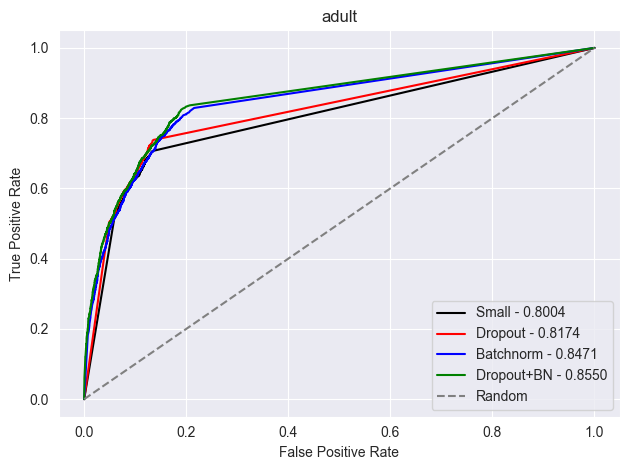

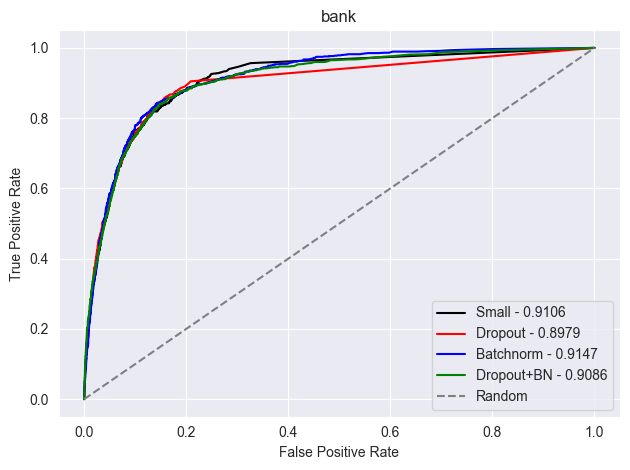

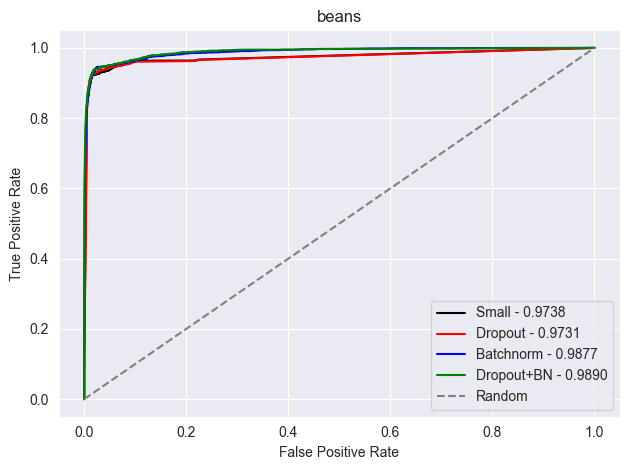

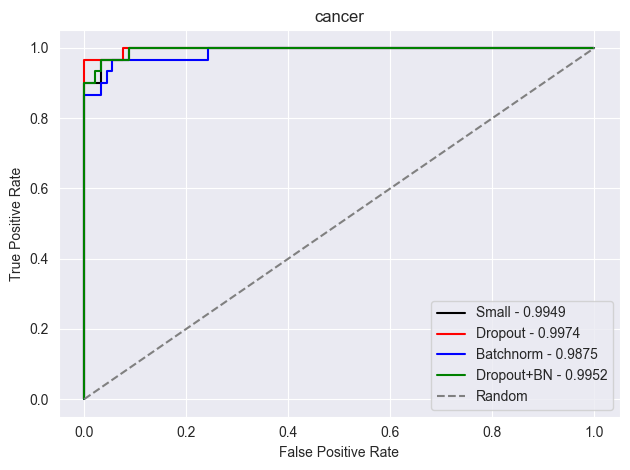

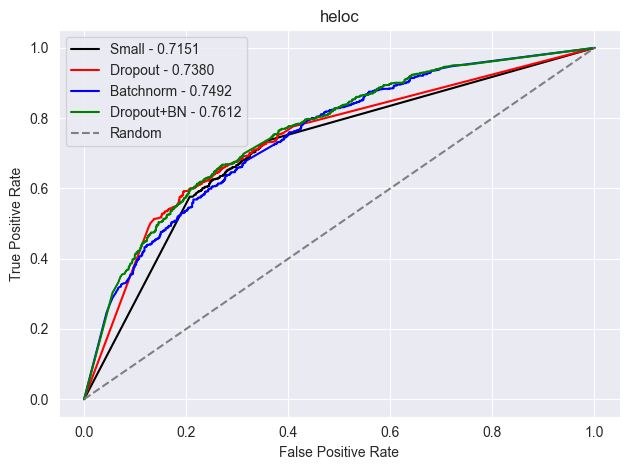

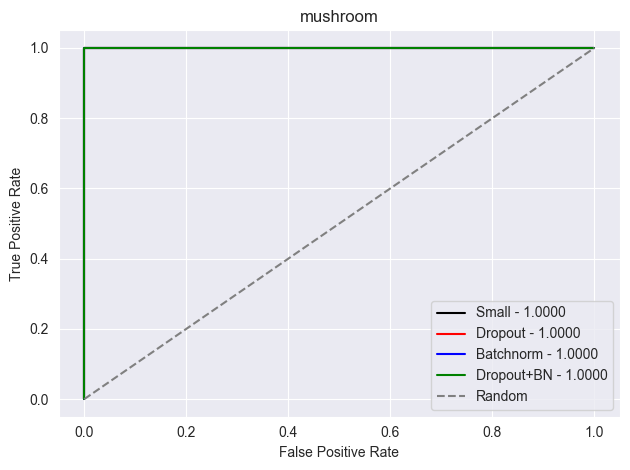

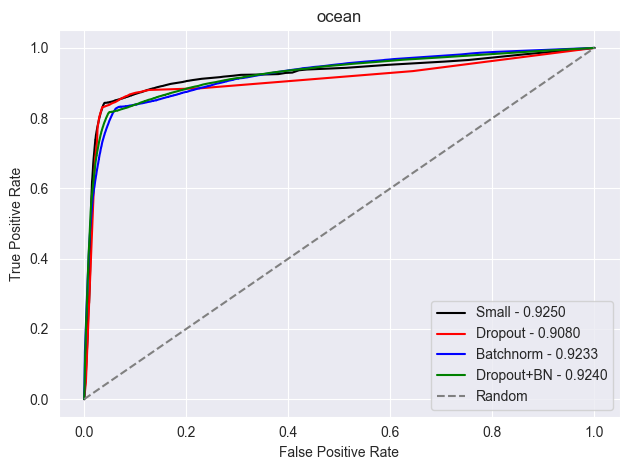

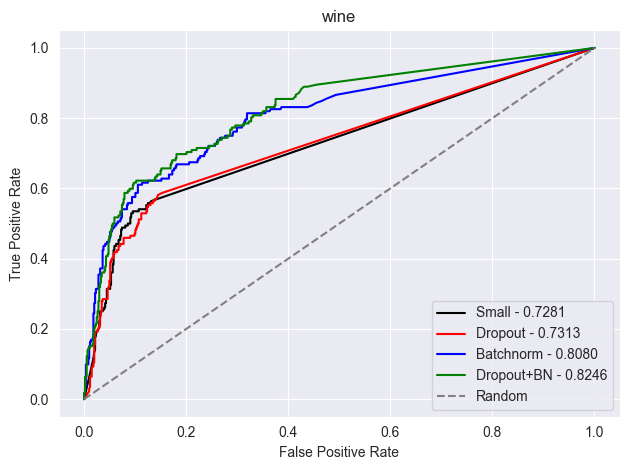

In [68]:
for idx, dataset in enumerate(dataset_list):
    plot_roc(y_vals[idx], results[idx][0], results[idx][1], results[idx][2], results[idx][3], dataset)